In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Add the 'src' directory to the system path
src_dir = os.path.abspath(os.path.join(os.getcwd(), "..", "src"))
sys.path.insert(0, src_dir)

# Now you can import the module
import standardised_pipeline_utils
from sklearn.preprocessing import MinMaxScaler
from joblib import dump, load
from scipy.stats import pearsonr

In [4]:
pearson = load('data/full_pearson.joblib')
pearson


,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A4GALT,AAAS,AACS,AACSP1,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
proteins,,,,,,,,,,,,,,,,,,,,,
A2M,0.248871,0.218735,0.000000,0.373828,0.102893,0.000000,0.000000,0.000000,0.000000,0.0,...,0.126432,0.000000,0.000000,0.0,0.000000,0.0,0.209332,0.177354,0.000000,0.000000
AAAS,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.157414,0.0,...,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.126199,-0.135638,0.127691
AACS,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.110278,0.000000,0.475468,0.0,...,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
AAGAB,0.107307,0.000000,0.000000,0.000000,0.000000,-0.137312,-0.122281,0.165741,0.000000,0.0,...,0.186194,0.000000,0.000000,0.0,0.000000,0.0,0.000000,-0.112258,0.221993,0.000000
AAK1,0.146338,0.132895,-0.111890,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,...,0.000000,0.140703,0.103788,0.0,0.000000,0.0,0.264591,0.299297,0.000000,0.123601
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZRANB2,0.000000,0.000000,-0.102888,0.000000,0.000000,0.000000,-0.163852,0.188706,0.000000,0.0,...,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,-0.201050,0.000000,0.190270
ZW10,0.000000,0.000000,0.000000,0.000000,0.153179,0.000000,0.000000,0.000000,0.000000,0.0,...,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.126669,0.000000,0.000000
ZWILCH,0.000000,0.000000,0.000000,0.000000,0.000000,-0.164772,-0.116266,0.162279,0.000000,0.0,...,0.220268,0.157534,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.153827,0.106739


### Plot protein - # correlated genes

how many zeros


In [15]:
zero_counts = (pearson == 0).sum(axis=1)

# Compute the number of genes correlated above thresholds
thresholds = [0.1, 0.2, 0.3]
thresh_counts = {t: (pearson.abs() > t).sum(axis=1) for t in thresholds}

In [16]:
# Create summary statistics
def print_summary():
    summary = pd.DataFrame({"Zero Correlations": zero_counts})
    for t in thresholds:
        summary[f"Correlated > {t}"] = thresh_counts[t]
    print(summary)

In [17]:
print_summary()

          Zero Correlations  Correlated > 0.1  Correlated > 0.2  \
proteins                                                          
A2M                   16621              9374              2238   
AAAS                  21095              4900               335   
AACS                  21674              4321               170   
AAGAB                 18766              7229               692   
AAK1                  16124              9871              2548   
...                     ...               ...               ...   
ZRANB2                18648              7347               811   
ZW10                  23115              2880                97   
ZWILCH                18555              7440               705   
ZYX                   17453              8542              1593   
ZZZ3                  18930              7065               701   

          Correlated > 0.3  
proteins                    
A2M                    270  
AAAS                     6  
AACS        

The following histogram displays how many genes per protein have correlations above 0.1 (absolute value). It helps to understand whether most genes have weak or strong correlations with each protein.

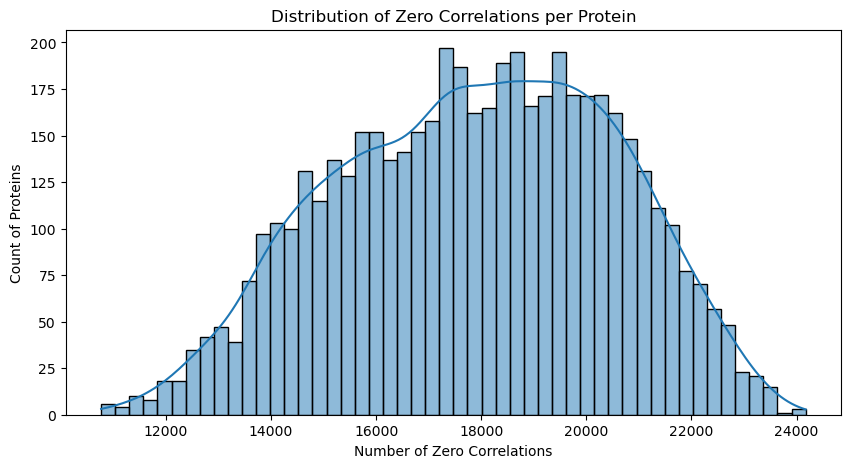

In [12]:
# Cell 1: Plot histogram of zero counts
plt.figure(figsize=(10, 5))
sns.histplot(zero_counts, bins=50, kde=True)
plt.xlabel("Number of Zero Correlations")
plt.ylabel("Count of Proteins")
plt.title("Distribution of Zero Correlations per Protein")
plt.show()

## Above 0.1 absolute correlation

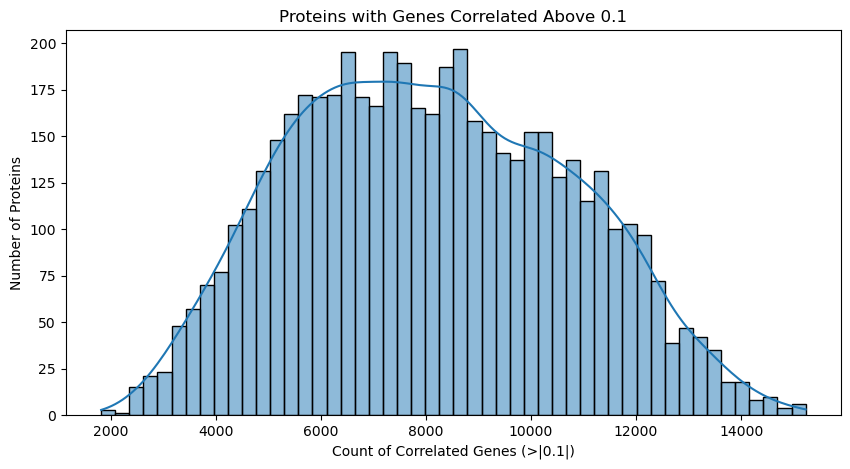

In [13]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.1], bins=50, kde=True)
plt.xlabel("Count of Correlated Genes (>|0.1|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.1")
plt.show()

## Above 0.2 absolute correlation

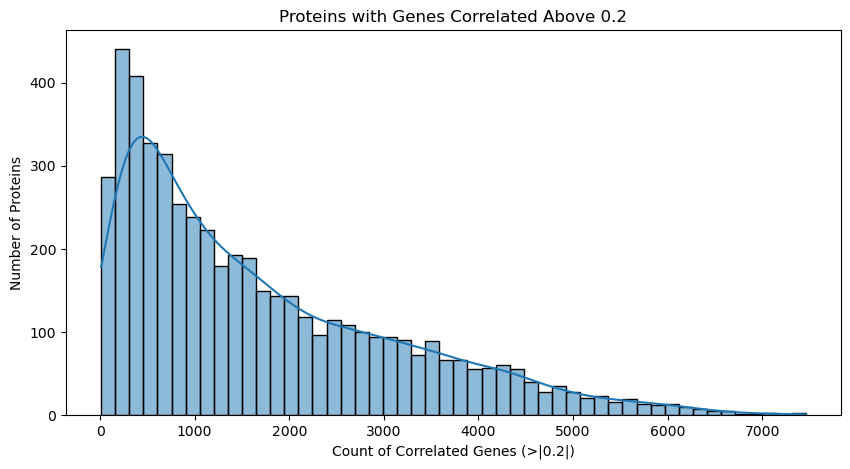

In [14]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.2], bins=50, kde=True)
plt.xlabel("Count of Correlated Genes (>|0.2|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.2")
plt.show()

## Above 0.3 absolute correlation

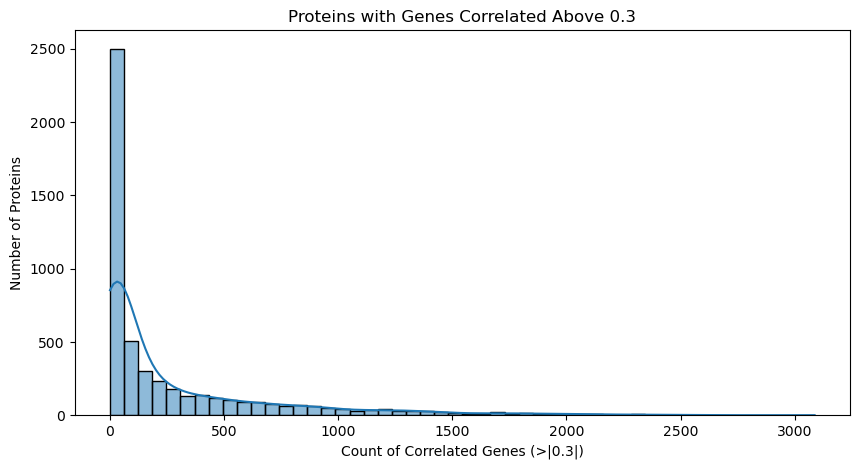

In [18]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.3], bins=50, kde=True)
plt.xlabel("Count of Correlated Genes (>|0.3|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.3")
plt.show()